# Experiment 16: NMR data efficiency

Compare 16A (E/F transfer, 200 training structures), 16B (direct NMR, 200), 16C (E/F transfer, 50) and 16D (direct NMR, 50) against experiment 15 (E/F transfer, 800). Transfer trains the final interaction layer and shared scalar readout; direct NMR trains the same network architecture from random initialisation with all layers trainable.

All five best checkpoints are evaluated afresh on the same 50 validation structures: 2,400 Si and 4,800 O sites. RMSE and MAE are in ppm; R² is calculated independently for each element. Targets are absolute DFT isotropic shieldings. All plots use the same axes for a given element and show every prediction. Only validation geometries and labels are read; no training or test evaluation is performed.

The code cells rerun inference and regenerate the saved PNG/PDF figures and prediction tables when executed.

## Results and interpretation

| Run | Training structures | Si RMSE | Si MAE | Si R² | O RMSE | O MAE | O R² |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 15 | 800 | 1.251 | 0.681 | 0.981 | 2.797 | 1.548 | 0.982 |
| 16A | 200 | 1.492 | 0.798 | 0.973 | 3.381 | 1.812 | 0.974 |
| 16B | 200 | 1.866 | 0.809 | 0.958 | 3.373 | 1.818 | 0.974 |
| 16C | 50 | 2.143 | 1.126 | 0.944 | 4.254 | 2.425 | 0.959 |
| 16D | 50 | 3.143 | 1.528 | 0.880 | 6.056 | 3.214 | 0.916 |

Errors are in ppm. Positive percentages below indicate lower error for transfer than for scratch.

At **200 training structures**, relative to direct training, Si RMSE is **20.02% lower** and O RMSE is **0.25% higher**; MAE reductions are 1.2% and 0.4% for Si and O, respectively.

At **50 training structures**, relative to direct training, Si RMSE is **31.79% lower** and O RMSE is **29.75% lower**; MAE reductions are 26.3% and 24.5% for Si and O, respectively.

Relative to experiment 15 (800 structures), 16A increases Si/O RMSE by 19.3% / 20.9%.

Relative to experiment 15 (800 structures), 16C increases Si/O RMSE by 71.3% / 52.1%.

15: best epoch 283, last epoch 583; 16A: best epoch 242, last epoch 542; 16B: best epoch 100, last epoch 400; 16C: best epoch 256, last epoch 556; 16D: best epoch 121, last epoch 421. Epoch numbers are one-based.

At 200 structures, oxygen performance is essentially tied, and the silicon MAEs are also close despite the larger RMSE difference. This is consistent with a difference concentrated in larger silicon errors. At 50 structures, transfer improves both RMSE and MAE substantially for both elements. Experiment 15 remains the most accurate of these five models. The strongest evidence for a transfer advantage in this comparison therefore comes from the 50-structure pair.

All five runs reached the configured 300 validation checks without improvement. The exported models exactly match their best checkpoints. Frozen embeddings and the first three interaction layers in the transfer models match the original E/F model, and the fourth layer changed. Recomputed validation objectives agree with saved scores within 0.05% relative tolerance.

These results compare practical transfer and direct-training procedures for one subset/seed at each size. They do not isolate pretraining from the effect of freezing most parameters. Validation was also used to select checkpoints, so these are not independent test estimates. Both procedures retain the established loss-normalisation constants derived from the 800-structure training split; the reduced-data claim concerns fitting on 200 or 50 structures under that established objective. No matched scratch run with 800 structures is included here.

## Load runs and check the comparison setup

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import torch, yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from IPython.display import display, Image
import matplotlib.pyplot as plt

ROOT = Path('/Users/louismcauliffe/code/research/NequIP_experiments')
sys.path.insert(0, str(ROOT))
import nmr_helpers
NAME = '16-TensorNequIP-NMR-DataEfficiency-Validation'
OUT = Path(globals().get('ARTIFACT_DIR', ROOT/'experiments'/(NAME+'-figures')))
OUT.mkdir(parents=True, exist_ok=True)
RUNS = {
    '15': '15-TensorNequIP-NMR-LastLayer-9148082',
    '16A': '16A-TensorNequIP-NMR-LastLayer-200-9149304',
    '16B': '16B-TensorNequIP-NMR-Scratch-200-9149305',
    '16C': '16C-TensorNequIP-NMR-LastLayer-50-9149380',
    '16D': '16D-TensorNequIP-NMR-Scratch-50-9149381',
}
SIZES = {'15':800, '16A':200, '16B':200, '16C':50, '16D':50}
TRANSFER = {'15','16A','16C'}
COLORS = {'15':'#238D8B','16A':'#3567BA','16B':'#CA7837','16C':'#7357AF','16D':'#BE5272'}
LABELS = {run: f'{run} · {"E/F transfer" if run in TRANSFER else "Direct NMR"} · {SIZES[run]} training' for run in RUNS}
torch.set_num_threads(4)
torch.set_default_dtype(torch.float32)
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def equal(a,b):
    if torch.is_tensor(a): return torch.is_tensor(b) and torch.equal(a,b)
    if isinstance(a,dict): return isinstance(b,dict) and a.keys()==b.keys() and all(equal(v,b[k]) for k,v in a.items())
    if isinstance(a,(list,tuple)): return type(a)==type(b) and len(a)==len(b) and all(equal(x,y) for x,y in zip(a,b))
    return a==b

VALID = ROOT/'data/nmr_iso/valid.xyz'
SOURCE = ROOT/'graph-pes-results/Kavanagh-Med-9059603/model.pt'
hashes = {str(p):sha(p) for p in [VALID,SOURCE]}
configs, summaries = {}, {}
for run,name in RUNS.items():
    folder = ROOT/'graph-pes-results'/name
    for relative in ['model.pt','checkpoints/best.ckpt','checkpoints/last.ckpt','train-config.yaml','summary.yaml']:
        p=folder/relative
        hashes[str(p)]=sha(p)
    configs[run]=yaml.safe_load((folder/'train-config.yaml').read_text())
    summaries[run]=yaml.safe_load((folder/'summary.yaml').read_text())
    c=configs[run]
    assert c['data']['valid']==configs['15']['data']['valid']
    assert c['data']['valid']['path']=='data/nmr_iso/valid.xyz'
    assert c['data'].get('test') is None
    assert c['loss']==configs['15']['loss']
    assert c['fitting']==configs['15']['fitting']
    assert c['general']['seed']==42
    if run!='15':
        assert c['data']['train']['n']==SIZES[run]
        assert c['data']['train']['seed']==42 and c['data']['train']['shuffle']
        assert c['data']['train']['path']=='data/nmr_iso/train.xyz'
    if run in TRANSFER:
        assert c['model']==configs['15']['model']
    else:
        assert c['model']==configs['15']['model']['+freeze_all_except']['model']['+nmr_helpers.shielding_transfer.from_energy_force_model']['model']
assert configs['16A']['data']==configs['16B']['data']
assert configs['16C']['data']==configs['16D']['data']
frames=read(VALID,index=':')
assert len(frames)==50
source=torch.load(SOURCE,map_location='cpu',weights_only=False).models['nequip']
print('Saved configs agree on validation data, architecture, loss and fitting settings; paired subsets use the same selection seed.')

Saved configs agree on validation data, architecture, loss and fitting settings; paired subsets use the same selection seed.


## Evaluate all five best checkpoints on validation geometries

In [2]:
all_sites, rows, provenance_rows = [], [], []
for run,name in RUNS.items():
    folder=ROOT/'graph-pes-results'/name
    model=torch.load(folder/'model.pt',map_location='cpu',weights_only=False)
    best=torch.load(folder/'checkpoints/best.ckpt',map_location='cpu',weights_only=False)
    last=torch.load(folder/'checkpoints/last.ckpt',map_location='cpu',weights_only=False)
    weights={k.removeprefix('model.'):v for k,v in best['state_dict'].items() if k.startswith('model.')}
    assert equal(model.state_dict(),weights), f'{run}: export differs from best checkpoint'
    assert model.models['nequip'].tensor_readout.weight.numel()==128
    frozen_verified=None
    if run in TRANSFER:
        nq=model.models['nequip']
        for part in ['Z_embedding','initial_node_embedding','edge_embedding']:
            assert equal(getattr(nq,part).state_dict(),getattr(source,part).state_dict())
        assert all(equal(nq.layers[i].state_dict(),source.layers[i].state_dict()) for i in range(3))
        assert not equal(nq.layers[3].state_dict(),source.layers[3].state_dict())
        frozen_verified=True
    model.eval().requires_grad_(False)
    early=next(v for k,v in last['callbacks'].items() if k.startswith('EarlyStopping'))
    checks=int(early['total_checks']-early['best_val_loss_check'])
    assert checks==int(summaries[run]['early_stopping/checks_since_best'])
    saved_loss=float(early['best_val_loss'])
    assert np.isclose(saved_loss,summaries[run]['early_stopping/best_valid_loss'])
    records=[]
    with torch.inference_mode():
        for i,atoms in enumerate(frames):
            graph=AtomicGraph.from_ase(atoms,cutoff=float(model.cutoff))
            assert not graph.properties and not graph.other
            y=np.asarray(atoms.arrays['MS_Iso_QM'],dtype=np.float64)
            p=model.predict(graph,['tensor'])['tensor'].cpu().numpy().astype(np.float64)
            assert p.shape==y.shape==(len(atoms),) and np.isfinite(p).all()
            records.append(pd.DataFrame(dict(run=run,structure=i,atom=np.arange(len(atoms)),element=atoms.get_chemical_symbols(),reference=y,prediction=p)))
    sites=pd.concat(records,ignore_index=True)
    all_sites.append(sites)
    for element in ['Si','O']:
        g=sites.query('element==@element')
        y,p=g.reference.to_numpy(),g.prediction.to_numpy()
        assert len(g)==(2400 if element=='Si' else 4800)
        rows.append(dict(run=run,training_structures=SIZES[run],method='Transfer' if run in TRANSFER else 'Scratch',
            element=element,N=len(g),RMSE=float(np.sqrt(np.mean((p-y)**2))),
            MAE=float(np.mean(np.abs(p-y))),R2=float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2))))
    rm={r['element']:r['RMSE'] for r in rows if r['run']==run}
    lc=configs[run]['loss']['isotropy']['+nmr_helpers.shared_head_training.ElementBalancedMSE']
    objective=lc['weight']*.5*(rm['Si']**2/lc['si_std']**2+rm['O']**2/lc['o_std']**2)
    relative_difference=abs(objective-saved_loss)/saved_loss
    assert np.isclose(objective,saved_loss,rtol=5e-4), (run,objective,saved_loss,relative_difference)
    provenance_rows.append(dict(run=run,training_structures=SIZES[run],best_epoch=int(best['epoch'])+1,
        last_epoch=int(last['epoch'])+1,best_optimizer_step=int(best['global_step']),
        last_optimizer_step=int(last['global_step']),checks_since_best=checks,
        stopping_status='Early-stopping patience reached' if checks>=configs[run]['fitting']['early_stopping']['patience'] else 'Patience not reached',
        trainable_parameters=int(summaries[run]['n_learnable_parameters']),
        wandb_runtime_minutes=float(summaries[run]['_runtime'])/60,
        frozen_backbone_verified=frozen_verified,export_matches_best=True,
        saved_best_loss=saved_loss,recomputed_best_loss=objective,loss_difference_percent=100*relative_difference))
    print(f'{run}: Si RMSE {rm["Si"]:.4f}, O RMSE {rm["O"]:.4f} ppm; best epoch {int(best["epoch"])+1}',flush=True)
    del model,best,last,weights
predictions=pd.concat(all_sites,ignore_index=True)
metrics=pd.DataFrame(rows)
provenance=pd.DataFrame(provenance_rows)
keys=['structure','atom','element','reference']
reference=predictions.query('run=="15"')[keys].reset_index(drop=True)
for run in RUNS:
    assert predictions.query('run==@run')[keys].reset_index(drop=True).equals(reference)
metrics.to_csv(OUT/'metrics.csv',index=False)
predictions.to_csv(OUT/'predictions.csv.gz',index=False)
provenance.to_csv(OUT/'checkpoint-provenance.csv',index=False)
display(metrics.round(4))
display(provenance[['run','best_epoch','last_epoch','checks_since_best','trainable_parameters','stopping_status']])

15: Si RMSE 1.2511, O RMSE 2.7967 ppm; best epoch 283
16A: Si RMSE 1.4920, O RMSE 3.3813 ppm; best epoch 242
16B: Si RMSE 1.8655, O RMSE 3.3729 ppm; best epoch 100
16C: Si RMSE 2.1434, O RMSE 4.2541 ppm; best epoch 256
16D: Si RMSE 3.1425, O RMSE 6.0559 ppm; best epoch 121


,run,training_structures,method,element,N,RMSE,MAE,R2
0,15,800,Transfer,Si,2400,1.2511,0.6805,0.9809
1,15,800,Transfer,O,4800,2.7967,1.5478,0.9822
2,16A,200,Transfer,Si,2400,1.4920,0.7985,0.9729
3,16A,200,Transfer,O,4800,3.3813,1.8117,0.9739
4,16B,200,Scratch,Si,2400,1.8655,0.8086,0.9576
5,16B,200,Scratch,O,4800,3.3729,1.8181,0.9741
6,16C,50,Transfer,Si,2400,2.1434,1.1257,0.9441
7,16C,50,Transfer,O,4800,4.2541,2.4253,0.9588
8,16D,50,Scratch,Si,2400,3.1425,1.5280,0.8798
9,16D,50,Scratch,O,4800,6.0559,3.2141,0.9164


,run,best_epoch,last_epoch,checks_since_best,trainable_parameters,stopping_status
0,15,283,583,300,141380,Early-stopping patience reached
1,16A,242,542,300,141380,Early-stopping patience reached
2,16B,100,400,300,738052,Early-stopping patience reached
3,16C,256,556,300,141380,Early-stopping patience reached
4,16D,121,421,300,738052,Early-stopping patience reached


## Individual parity plots for experiments 16A–D

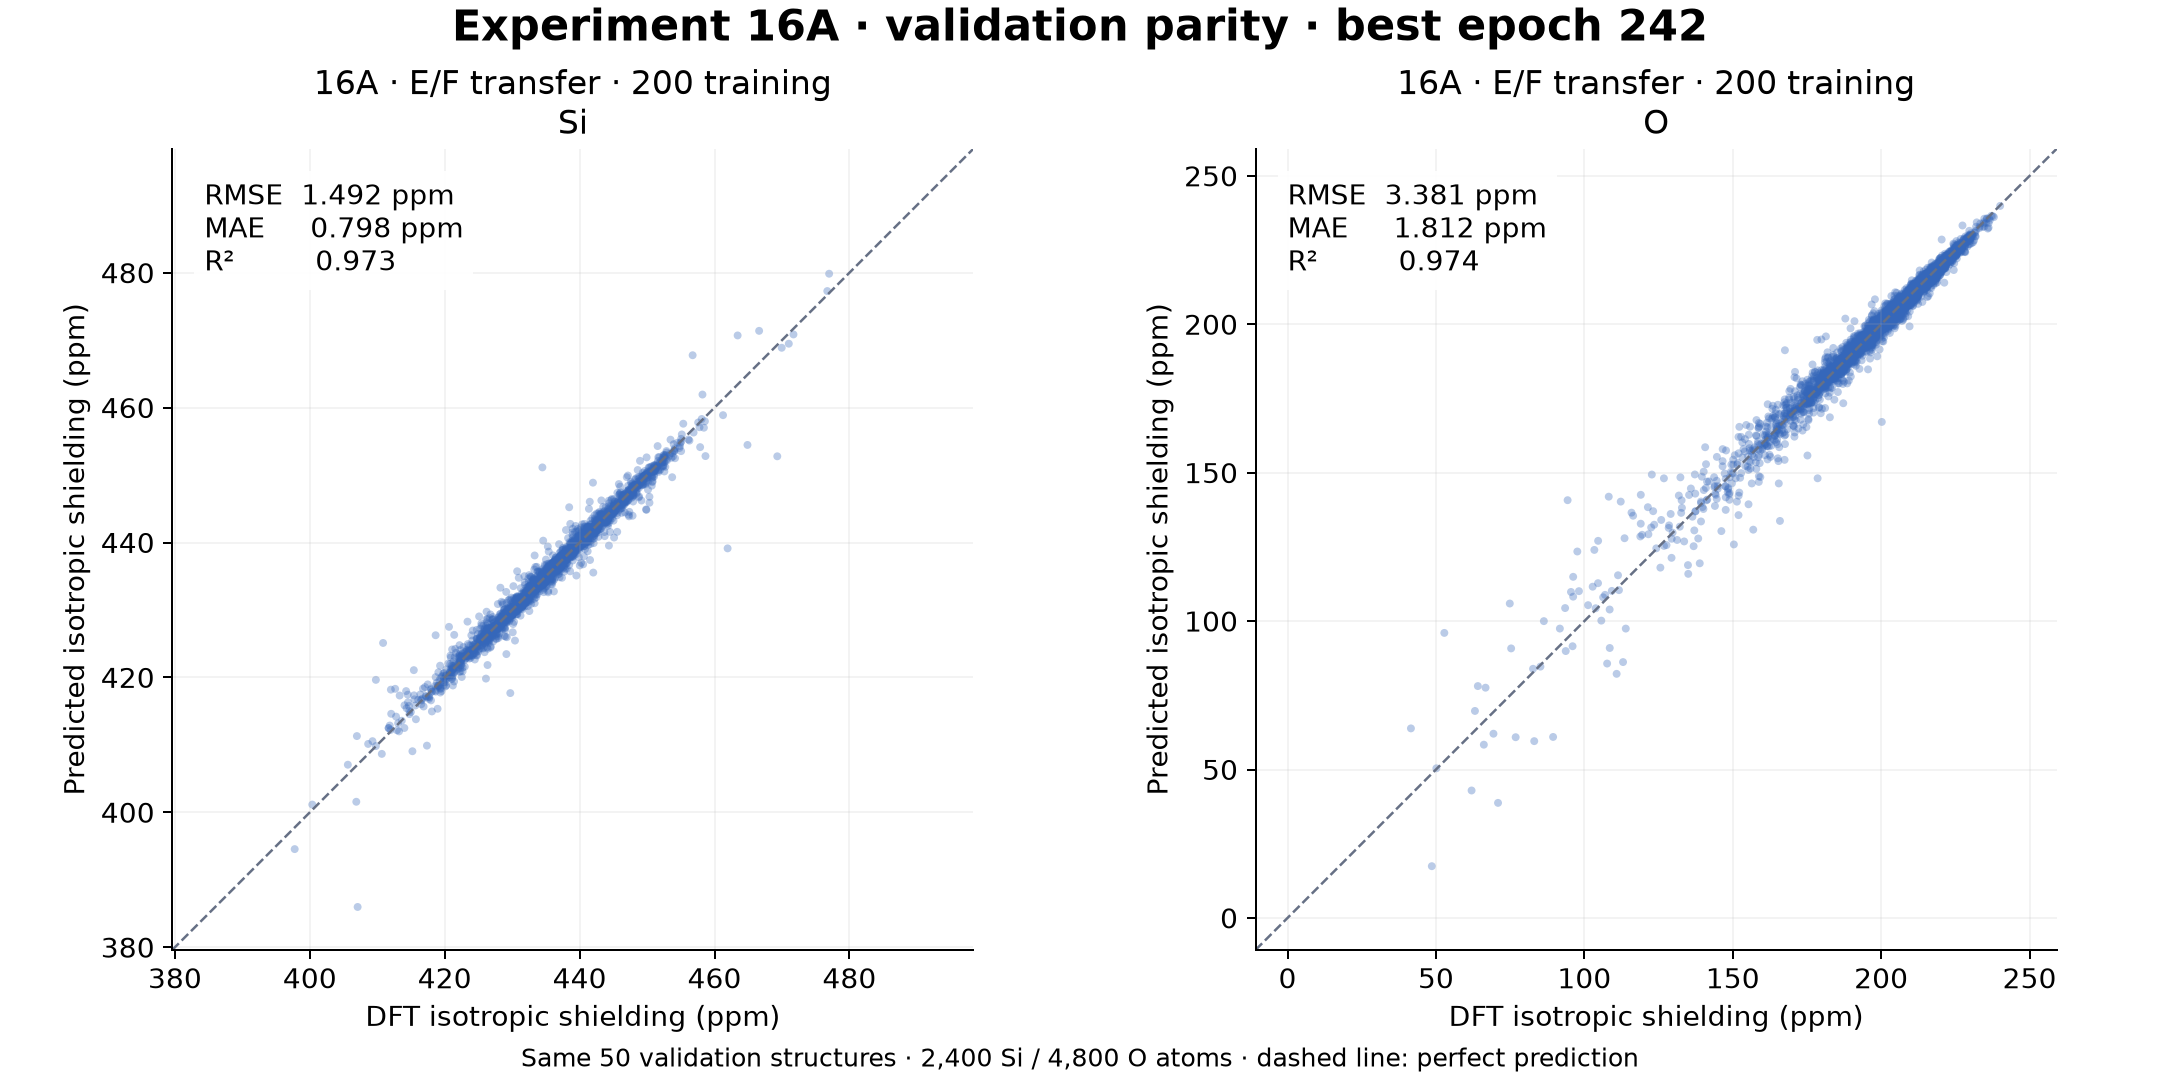

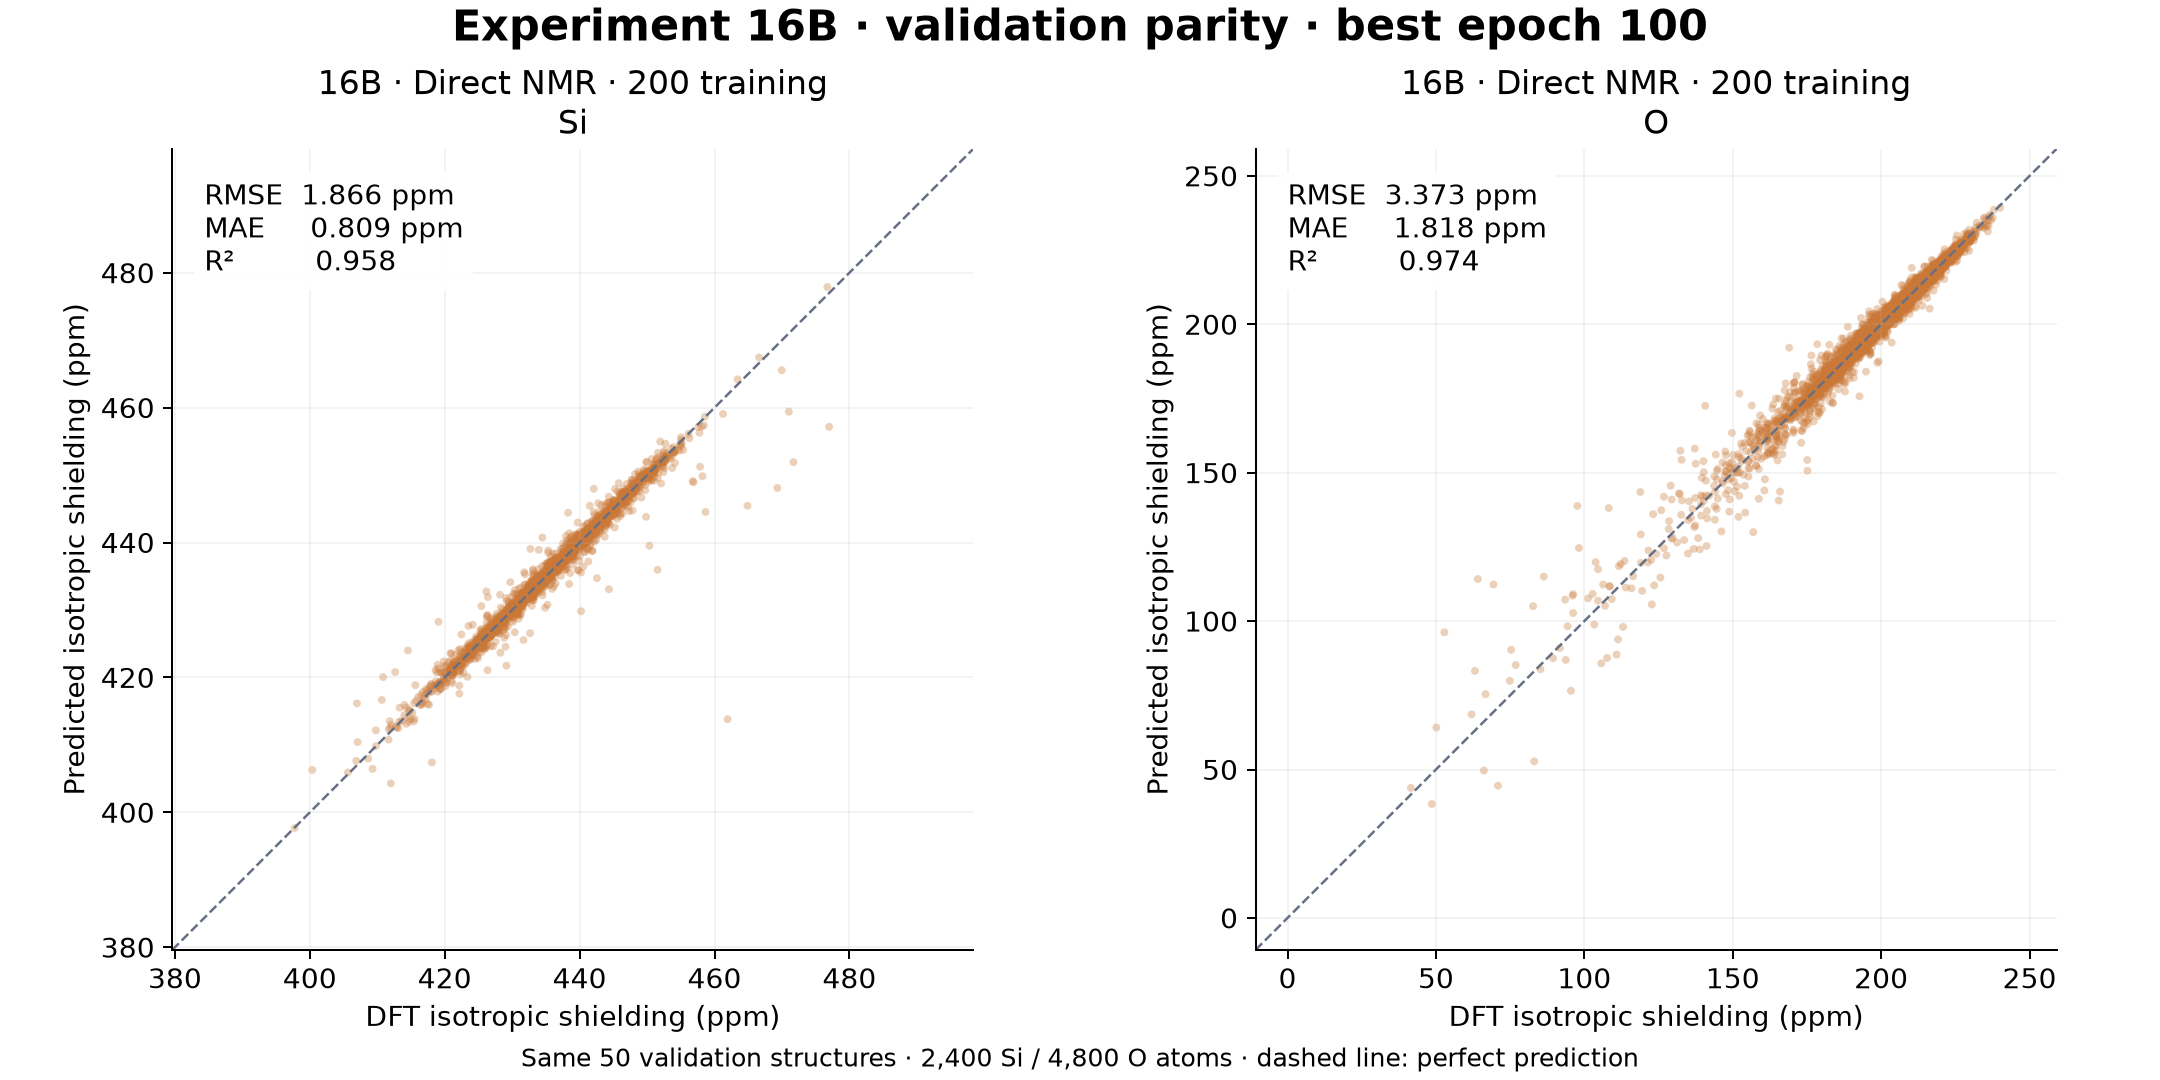

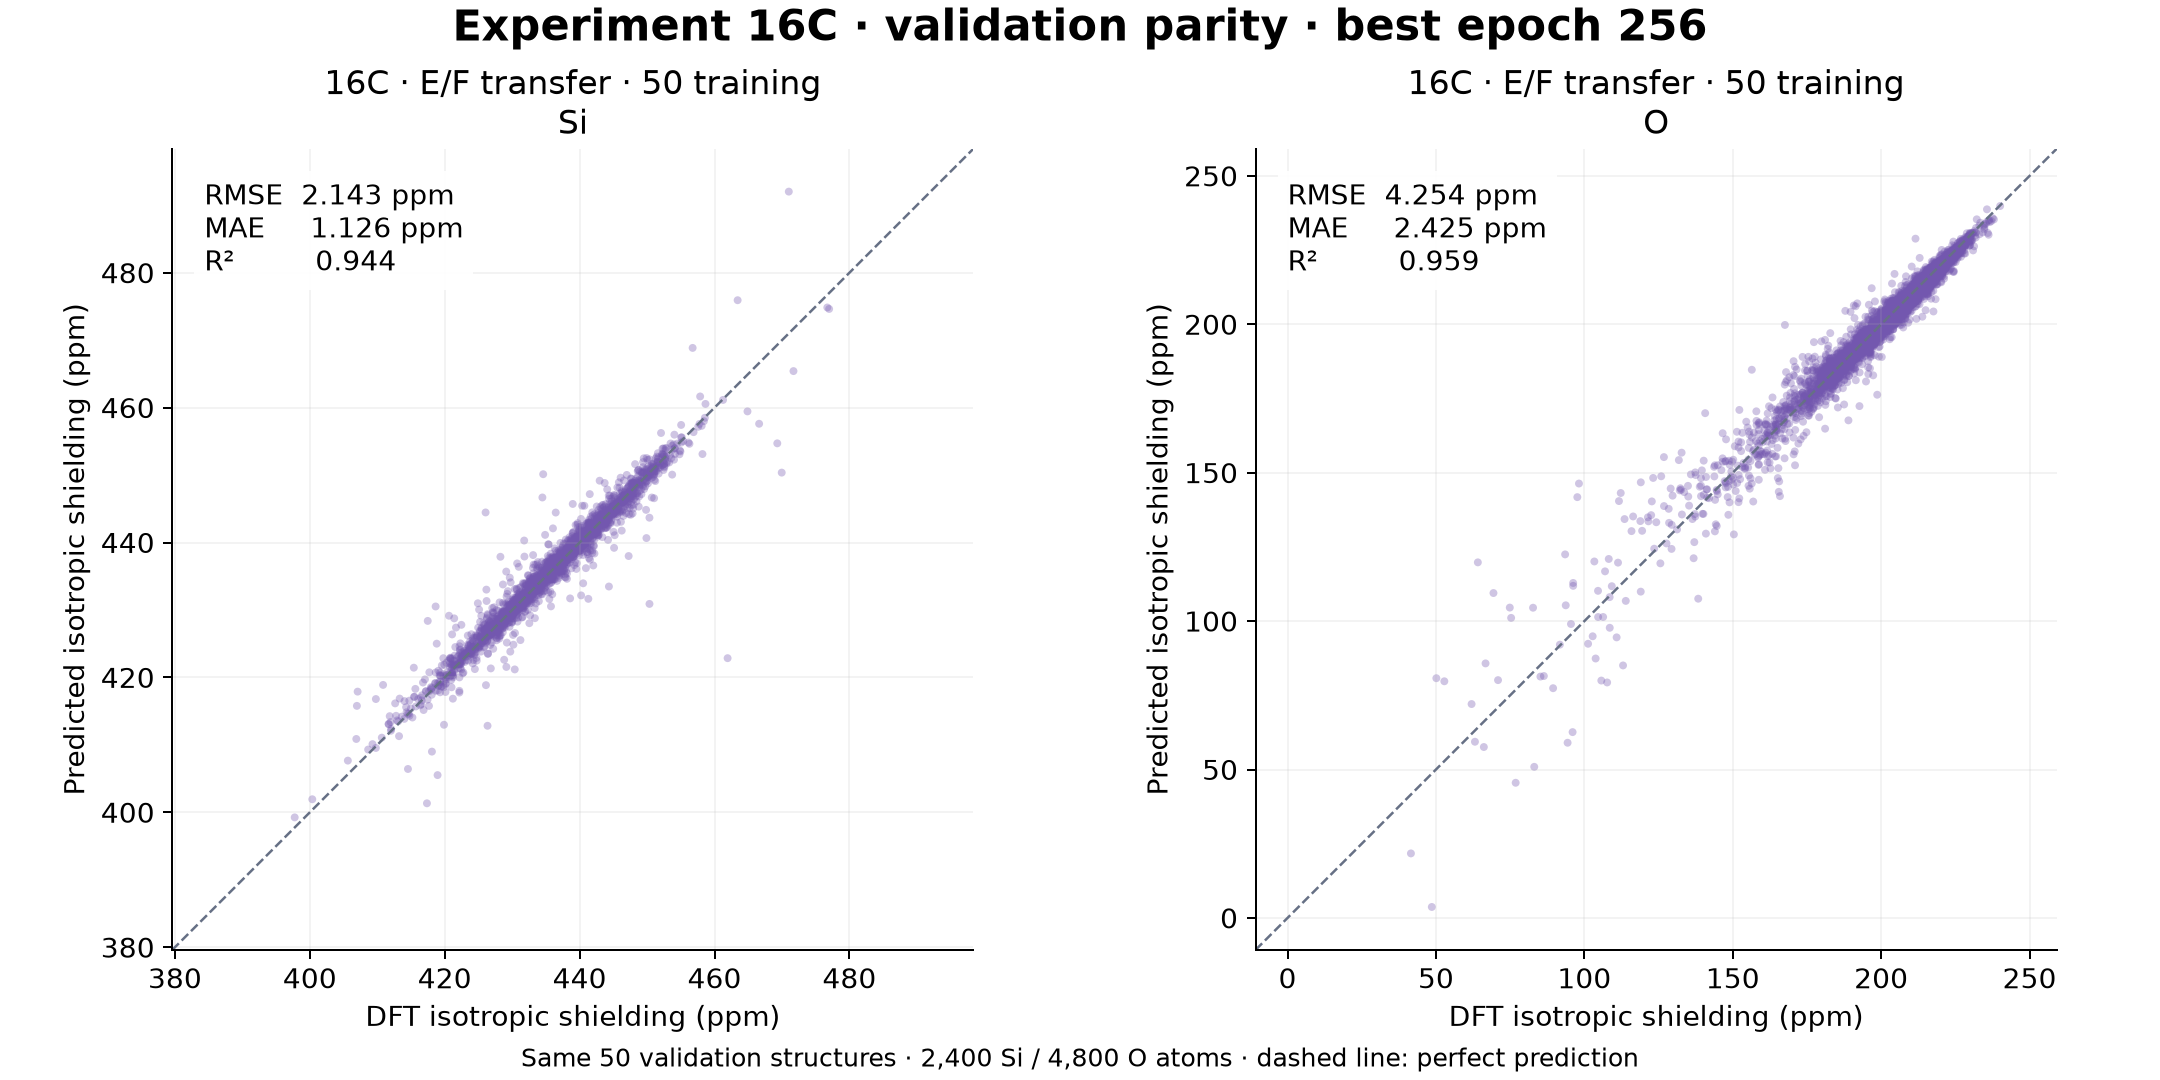

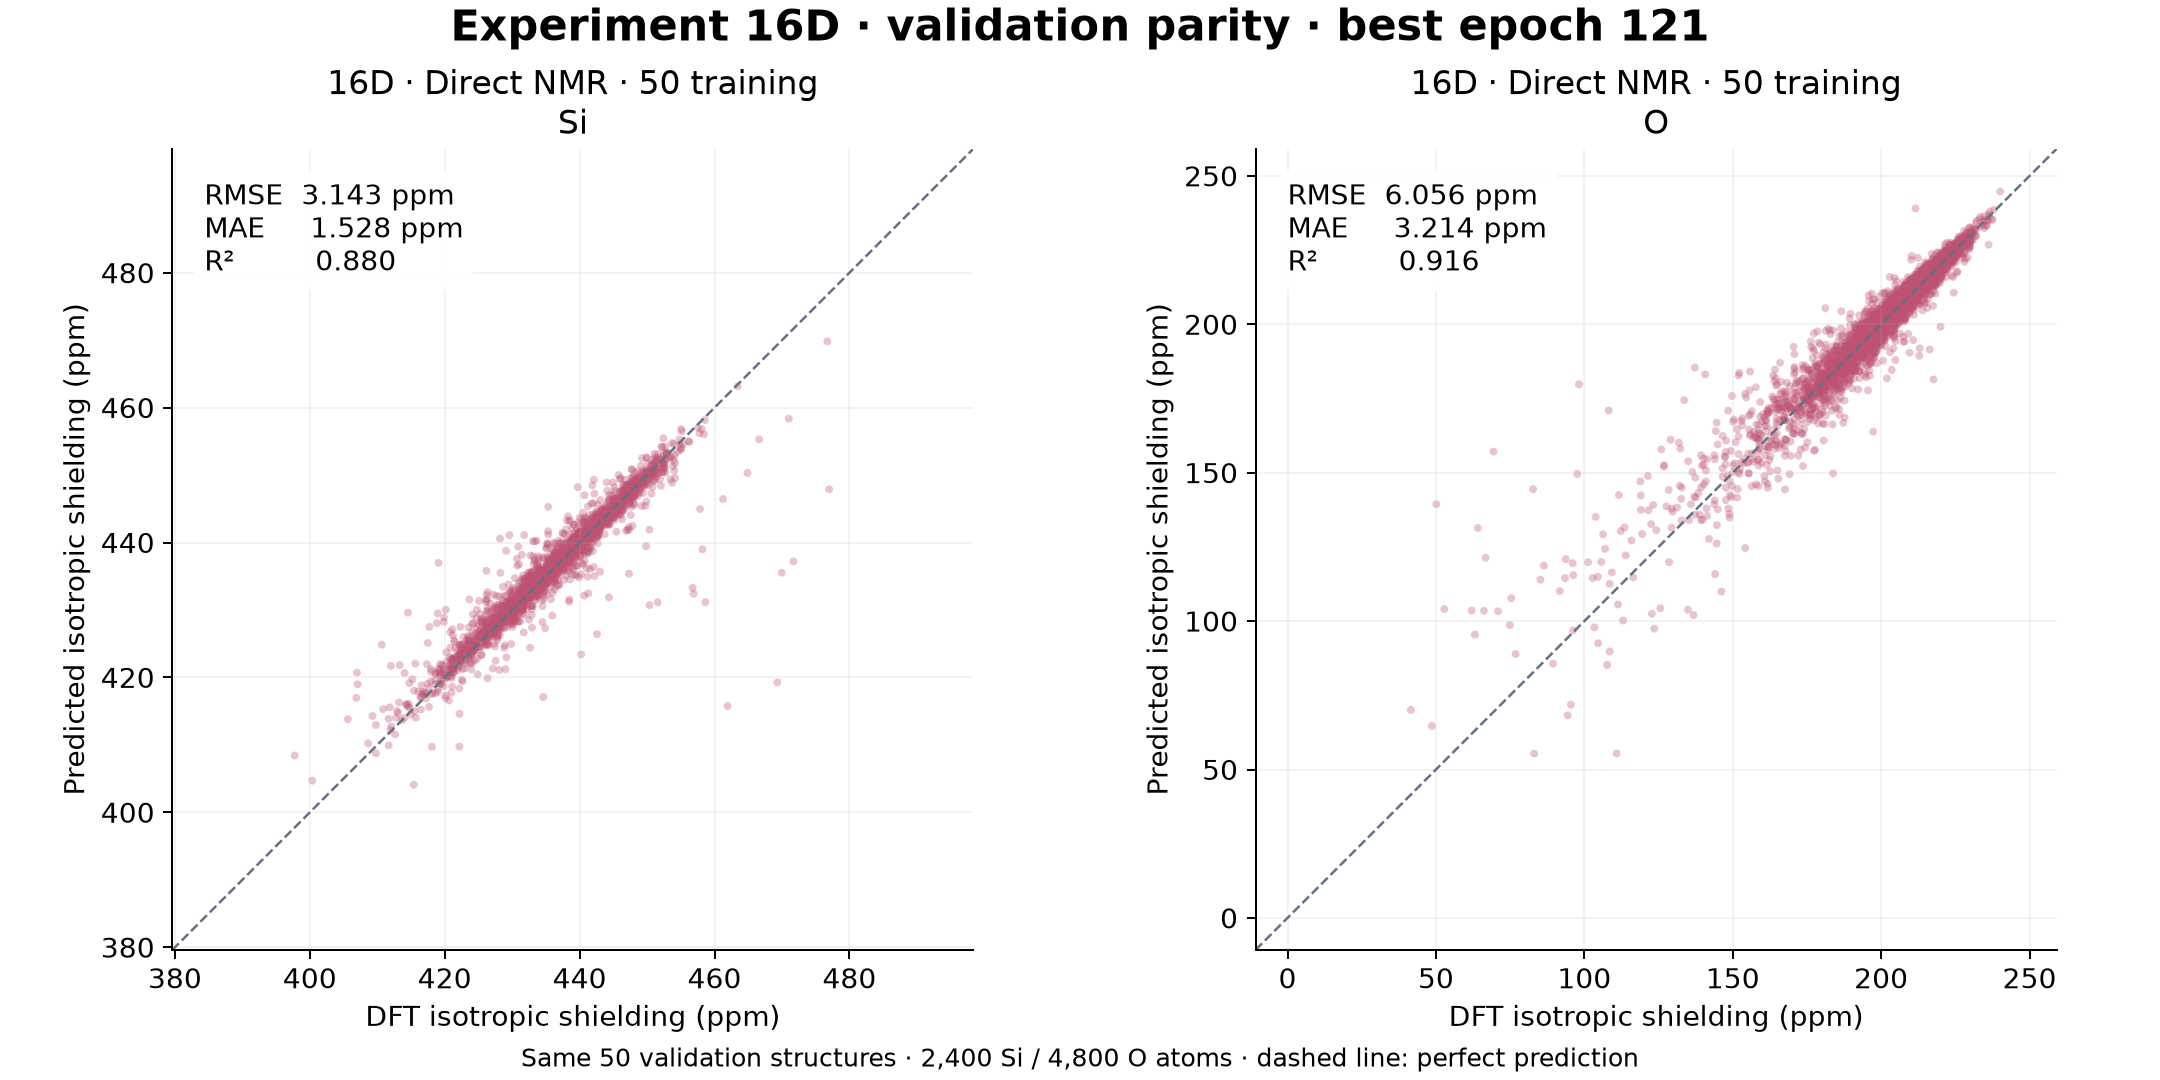

In [3]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,
    'axes.spines.right':False,'savefig.facecolor':'white'})
limits={}
for element in ['Si','O']:
    g=predictions.query('element==@element')
    lo=min(g.reference.min(),g.prediction.min()); hi=max(g.reference.max(),g.prediction.max())
    pad=.06*(hi-lo)
    limits[element]=(lo-pad,hi+pad)
def panel(ax,run,element):
    g=predictions.query('run==@run and element==@element')
    r=metrics.query('run==@run and element==@element').iloc[0]
    ax.scatter(g.reference,g.prediction,s=10,alpha=.34,color=COLORS[run],edgecolors='none',rasterized=True)
    ax.plot(limits[element],limits[element],'--',color='#667085',lw=1)
    ax.set(xlim=limits[element],ylim=limits[element],aspect='equal',title=f'{LABELS[run]}\n{element}',
        xlabel='DFT isotropic shielding (ppm)',ylabel='Predicted isotropic shielding (ppm)')
    ax.text(.04,.96,f'RMSE  {r.RMSE:.3f} ppm\nMAE     {r.MAE:.3f} ppm\nR²         {r.R2:.3f}',transform=ax.transAxes,va='top',
        bbox=dict(facecolor='white',alpha=.95,edgecolor='none'))
    ax.grid(alpha=.15)
def save_and_show(fig,filename):
    for ext in ['png','pdf']: fig.savefig(OUT/f'{filename}.{ext}',dpi=180)
    plt.close(fig)
    display(Image(filename=str(OUT/f'{filename}.png')))
for run in ['16A','16B','16C','16D']:
    fig,axes=plt.subplots(1,2,figsize=(12,6),layout='constrained')
    for ax,element in zip(axes,['Si','O']): panel(ax,run,element)
    epoch=provenance.set_index('run').loc[run,'best_epoch']
    fig.suptitle(f'Experiment {run} · validation parity · best epoch {epoch}',fontsize=17,weight='bold')
    fig.supxlabel('Same 50 validation structures · 2,400 Si / 4,800 O atoms · dashed line: perfect prediction',fontsize=10)
    save_and_show(fig,f'validation-parity-{run}')

## Side-by-side comparisons with experiment 15

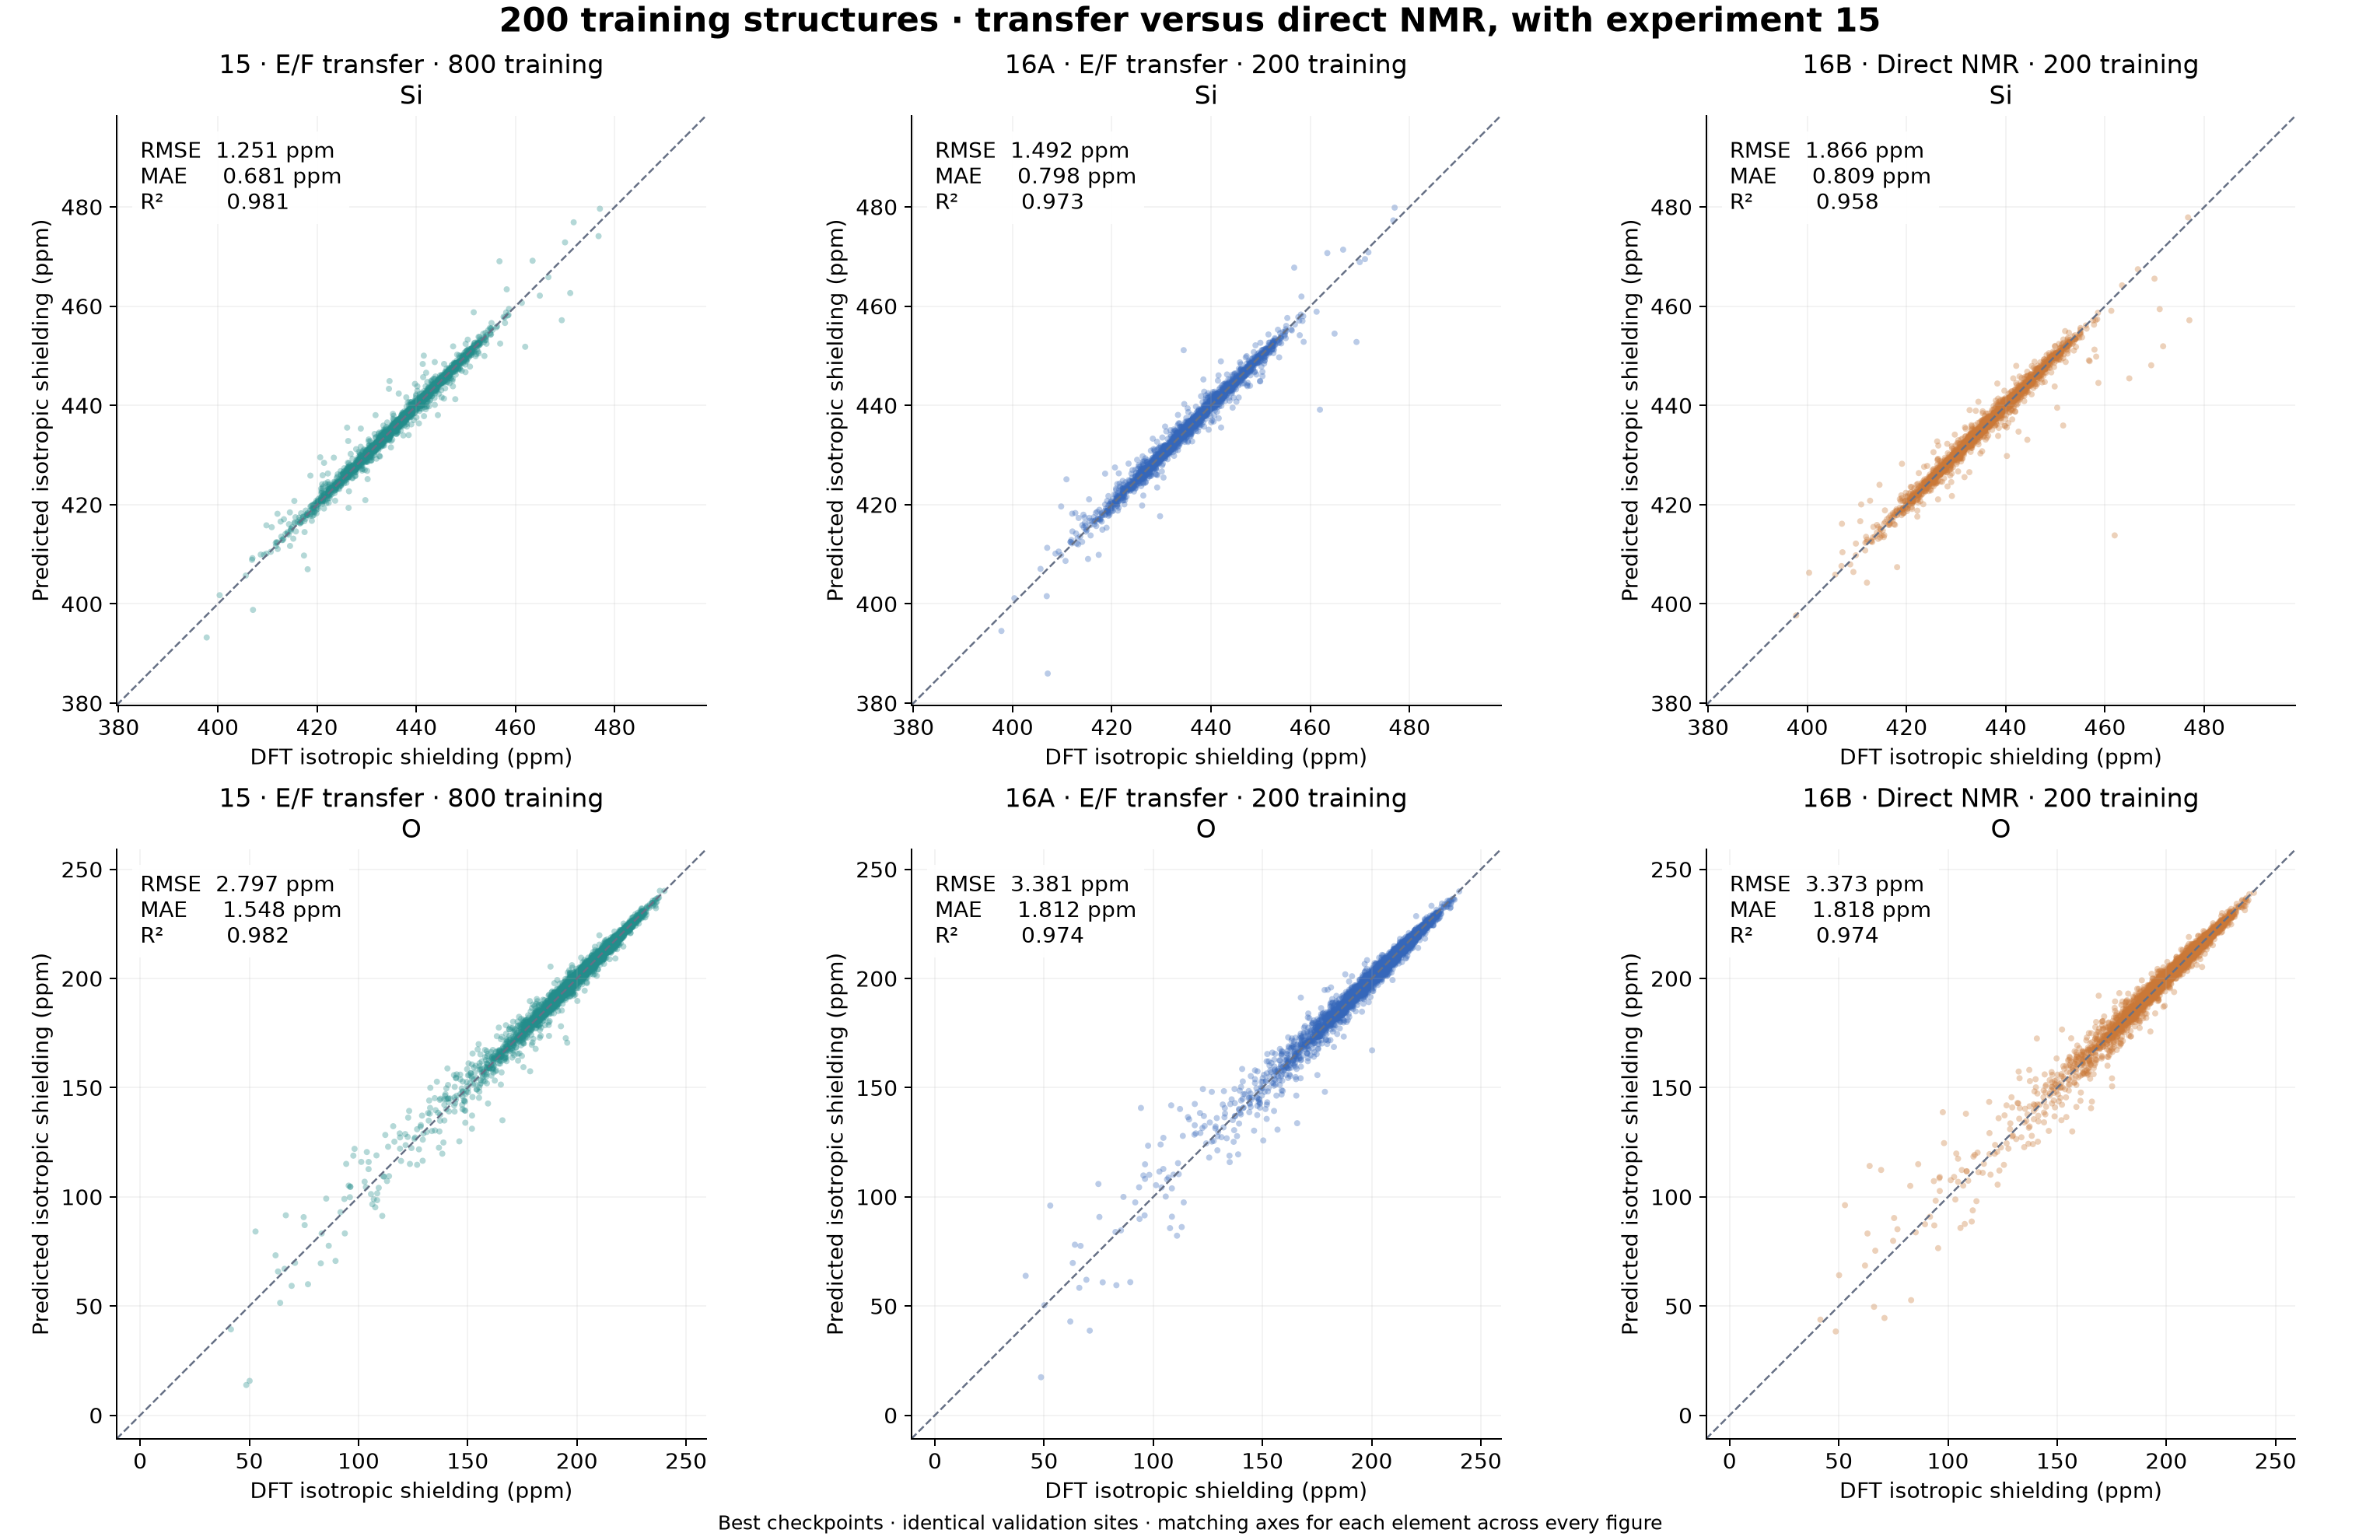

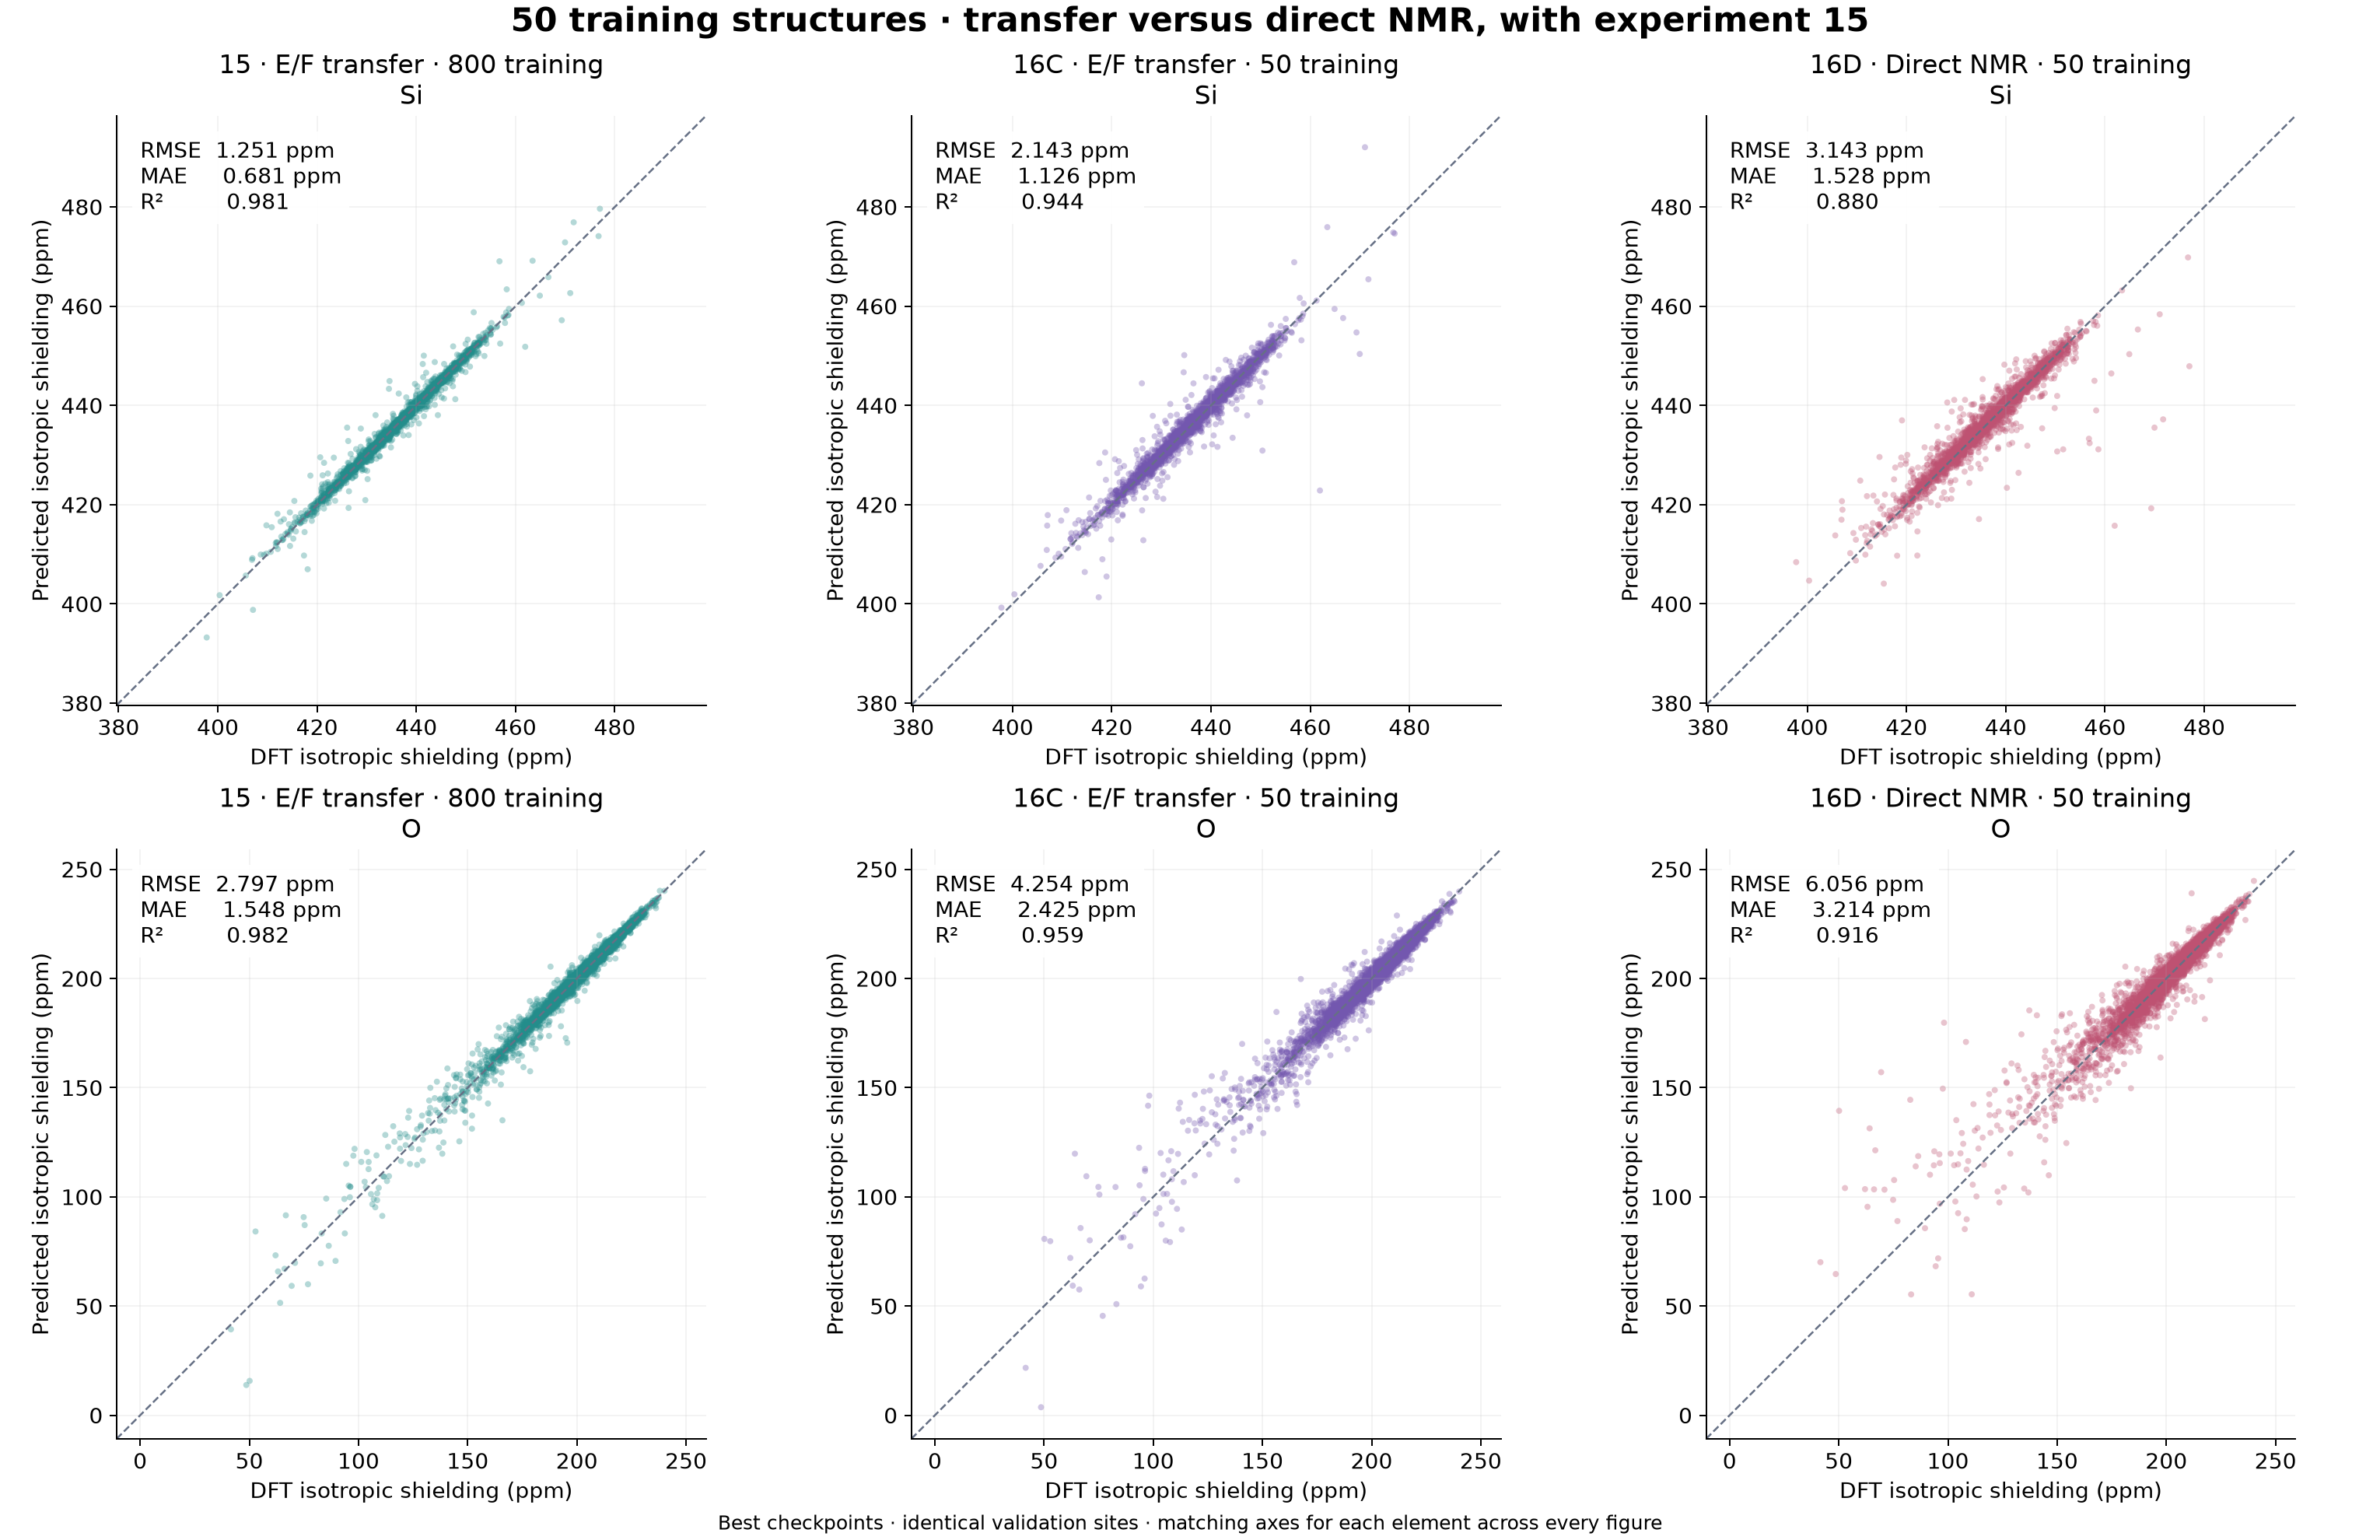

In [4]:
for size,pair in [(200,['16A','16B']),(50,['16C','16D'])]:
    fig,axes=plt.subplots(2,3,figsize=(17,11),layout='constrained')
    for row,element in enumerate(['Si','O']):
        for col,run in enumerate(['15',*pair]): panel(axes[row,col],run,element)
    fig.suptitle(f'{size} training structures · transfer versus direct NMR, with experiment 15',fontsize=17,weight='bold')
    fig.supxlabel('Best checkpoints · identical validation sites · matching axes for each element across every figure',fontsize=10)
    save_and_show(fig,f'validation-parity-15-vs-{pair[0]}-vs-{pair[1]}')

## Quantify changes against experiment 15 and the paired scratch controls

In [5]:
comparison=metrics.copy()
baseline=metrics.query('run=="15"').set_index('element')
for metric in ['RMSE','MAE']:
    comparison[f'{metric}_increase_vs_15_pct']=[100*(row[metric]/baseline.loc[row.element,metric]-1) for _,row in comparison.iterrows()]
comparison['R2_change_vs_15']=[row.R2-baseline.loc[row.element,'R2'] for _,row in comparison.iterrows()]
paired=[]
for transfer,scratch in [('16A','16B'),('16C','16D')]:
    for element in ['Si','O']:
        t=metrics.query('run==@transfer and element==@element').iloc[0]
        s=metrics.query('run==@scratch and element==@element').iloc[0]
        paired.append(dict(training_structures=int(t.training_structures),element=element,transfer=transfer,scratch=scratch,
            RMSE_reduction_pct=100*(1-t.RMSE/s.RMSE),MAE_reduction_pct=100*(1-t.MAE/s.MAE),R2_gain=t.R2-s.R2))
paired=pd.DataFrame(paired)
display(comparison[['run','element','RMSE','MAE','R2','RMSE_increase_vs_15_pct','MAE_increase_vs_15_pct','R2_change_vs_15']].round(4))
display(paired.round(4))
comparison.to_csv(OUT/'comparison-vs-15.csv',index=False)
paired.to_csv(OUT/'paired-transfer-vs-scratch.csv',index=False)
assert all(sha(p)==digest for p,digest in hashes.items()), 'An input changed during evaluation'
(OUT/'manifest.json').write_text(json.dumps(dict(input_sha256=hashes,runs=RUNS,
    evaluated_split='validation',validation_structures=50,Si_sites=2400,O_sites=4800,
    fresh_predictions_for_all_five_runs=True,training_or_test_labels_read=False,
    saved_loss_relative_tolerance=5e-4,metrics='Unweighted per-element atom-pooled RMSE, MAE and R2; ppm for errors',
    subset_evidence='Saved configs match n and seed within pairs; subset nesting was verified during config smoke checks.',
    limitations=['Single subset and training seed','Validation split used for checkpoint selection',
        'Transfer and scratch differ in trainable layers','Fixed loss constants were originally estimated from all 800 training structures']),indent=2))

Out[0]: 6489


,run,element,RMSE,MAE,R2,RMSE_increase_vs_15_pct,MAE_increase_vs_15_pct,R2_change_vs_15
0,15,Si,1.2511,0.6805,0.9809,0.0000,0.0000,0.0000
1,15,O,2.7967,1.5478,0.9822,0.0000,0.0000,0.0000
2,16A,Si,1.4920,0.7985,0.9729,19.2563,17.3289,-0.0080
3,16A,O,3.3813,1.8117,0.9739,20.9056,17.0464,-0.0082
4,16B,Si,1.8655,0.8086,0.9576,49.1062,18.8106,-0.0233
5,16B,O,3.3729,1.8181,0.9741,20.6037,17.4643,-0.0081
6,16C,Si,2.1434,1.1257,0.9441,71.3162,65.4082,-0.0369
7,16C,O,4.2541,2.4253,0.9588,52.1115,56.6932,-0.0234
8,16D,Si,3.1425,1.5280,0.8798,151.1743,124.5211,-0.1012
9,16D,O,6.0559,3.2141,0.9164,116.5392,107.6530,-0.0658


,training_structures,element,transfer,scratch,RMSE_reduction_pct,MAE_reduction_pct,R2_gain
0,200,Si,16A,16B,20.0193,1.2471,0.0153
1,200,O,16A,16B,-0.2503,0.3557,-0.0001
2,50,Si,16C,16D,31.7939,26.3285,0.0643
3,50,O,16C,16D,29.7534,24.5408,0.0423
